# 06 · Calidad de los datos y transformaciones

En el notebook 01 vimos por encima dos problemas de calidad: incrementos diarios negativos y filas con más
positivos que tests. Aquí los revisamos a fondo, junto con el resto de incoherencias entre columnas, y aplicamos
dos transformaciones justificadas.

1. **Incoherencias entre columnas:** valores que no pueden ser ciertos a la vez.
2. **Incrementos frente a acumulados:** si las dos familias de columnas cuentan lo mismo.
3. **Correcciones** (incrementos negativos) por estado y fecha.
4. **Días sin publicar:** ceros que no son ceros.
5. **Media móvil de 7 días** para las series temporales.
6. **Escala logarítmica** para las distribuciones sesgadas.
7. **Resumen:** cada tipo de dato dudoso y cómo se trata.

Todo el código nuevo está en `src/calidad.py` y `src/transformaciones.py`.

## 0. Preparación

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.calidad import (REGLAS_COHERENCIA, comprobar_incrementos, diferencia_totales, marcar_ceros_sin_publicar,
                         resumir_correcciones, resumir_marcas, revisar_coherencia, tratar_calidad)
from src.graficos import (AZUL, GRIS, NARANJA, TEXTO, TEXTO_SUAVE, VERDE, aplicar_estilo, formato_miles, miles)
from src.limpieza import COLUMNAS_INCREMENTO, cargar_datos, convertir_fecha, seleccionar_y_renombrar
from src.transformaciones import asimetria, efecto_dia_semana, log10_1p, media_movil
from src.variables import positividad_7d

aplicar_estilo()

RUTA_CRUDO = RAIZ / "data" / "raw" / "covid_states_daily.csv"
RUTA_POBLACION = RAIZ / "data" / "processed" / "covid_estados_poblacion.csv"
if not RUTA_POBLACION.exists():
    raise FileNotFoundError("Ejecuta antes python -m src.pipeline o los notebooks 01, 02, 03 y 05: generan "
                            + str(RUTA_POBLACION.relative_to(RAIZ)))

# Datos sin limpiar (con los incrementos negativos tal cual), con las columnas ya renombradas.
sin_limpiar = seleccionar_y_renombrar(convertir_fecha(cargar_datos(RUTA_CRUDO)))
sin_limpiar = sin_limpiar.sort_values(["estado", "fecha"]).reset_index(drop=True)

# Datos limpios con variables y población (notebooks 01 a 05).
datos = pd.read_csv(RUTA_POBLACION, parse_dates=["fecha", "semana"])
print("Sin limpiar:", sin_limpiar.shape, "| limpios:", datos.shape)

Sin limpiar: (20780, 15) | limpios: (20780, 32)


## 1. Incoherencias entre columnas

Hay combinaciones de valores que no pueden ser ciertas a la vez. Comprobamos cinco reglas en los datos sin
limpiar:

| Regla | Por qué es imposible o dudoso |
|---|---|
| Más positivos que tests | Cada positivo sale de un test. |
| Más muertes que casos | Cada muerte por COVID es un caso confirmado o probable. |
| Más pacientes en UCI que hospitalizados | La UCI está dentro del hospital. |
| Más pacientes con respirador que en UCI | Normalmente el respirador se pone en la UCI (en momentos de saturación puede haber excepciones). |
| Recuperados más muertes por encima de los casos | Un caso no puede acabar de dos formas. |

In [2]:
descripciones = {nombre: texto for nombre, (texto, _) in REGLAS_COHERENCIA.items()}
marcas = revisar_coherencia(sin_limpiar)
resumir_marcas(sin_limpiar, marcas, descripciones)

,descripcion,filas,estados,principales,desde,hasta
marca,,,,,,
positivos_sobre_tests,Más positivos acumulados que tests acumulados,59,3,"WA (38), MI (15), GA (6)",2020-01-22,2020-03-24
muertes_sobre_casos,Más muertes acumuladas que casos acumulados,0,0,,NaT,NaT
uci_sobre_hospitalizados,Más pacientes en UCI que hospitalizados,0,0,,NaT,NaT
ventilador_sobre_uci,Más pacientes con respirador que en UCI,57,9,"PR (33), HI (6), KS (5)",2020-04-09,2021-03-02
recuperados_sobre_casos,Recuperados más muertes por encima de los casos,69,1,IA (69),2020-12-29,2021-03-07


- **Dos reglas se cumplen siempre:** no hay ningún día con más muertes que casos ni con más pacientes en UCI que
  hospitalizados.
- **Tres reglas se incumplen**, y cada una en muy pocos estados. Las vemos una a una.

### 1.1 Más positivos que tests

Es el caso más claro de dato imposible.

In [3]:
positivos = sin_limpiar[marcas["positivos_sobre_tests"]]
positivos.groupby("estado").agg(
    desde=("fecha", "min"), hasta=("fecha", "max"), filas=("fecha", "size"),
    tests_acum_max=("tests_acum", "max"), casos_acum_max=("casos_acum", "max"),
    unidad_de_tests=("fuente_tests", "first"),
)

,desde,hasta,filas,tests_acum_max,casos_acum_max,unidad_de_tests
estado,,,,,,
GA,2020-03-04,2020-03-09,6,6.0,12.0,totalTestsViral
MI,2020-03-10,2020-03-24,15,9356.0,10155.0,totalTestsViral
WA,2020-01-22,2020-02-28,38,0.0,15.0,totalTestEncountersViral


Las 59 filas son de **Washington, Michigan y Georgia** y todas están **antes del 25 de marzo de 2020**, en los
primeros días de cada serie. Los estados empezaron a publicar los positivos antes que los tests, o publicaban
solo una parte de los tests (por ejemplo, los del laboratorio estatal y no los de los privados). No es que hubiera
más positivos que pruebas: es que **la cifra de tests de esos días está incompleta**.

En el notebook 03 ya vimos su consecuencia: 17 valores de positividad por encima del 100 %, casi todos en
Michigan.

**Tratamiento:** los tests de esas filas pasan a `NaN` y la fila queda marcada en `positivos_sobre_tests`. Los
casos sí se conservan: son la parte fiable de la fila.

### 1.2 Más pacientes con respirador que en UCI

In [4]:
respirador = sin_limpiar[marcas["ventilador_sobre_uci"]]
print("Filas:", len(respirador), "| estados:", respirador["estado"].nunique())
print("Diferencia típica (respirador - UCI):",
      (respirador["ventilador_actuales"] - respirador["uci_actuales"]).median(), "pacientes")
respirador["estado"].value_counts().to_frame("filas").T

Filas: 57 | estados: 9
Diferencia típica (respirador - UCI): 4.0 pacientes


estado,PR,HI,KS,RI,SD,DC,NJ,WI,WV
filas,33,6,5,5,4,1,1,1,1


57 filas, más de la mitad de **Puerto Rico**. Es posible que en momentos de saturación hubiera pacientes con
respirador fuera de la UCI, o que algunos estados contaran la UCI de forma distinta. No se puede saber con estos
datos.

**Tratamiento:** se marca (`ventilador_sobre_uci`) y no se toca. Los pacientes con respirador no se usan en las
conclusiones: menos de la mitad de las filas tienen el dato (notebook 04).

### 1.3 Recuperados por encima de lo posible

In [5]:
recuperados = sin_limpiar[marcas["recuperados_sobre_casos"]]
print("Estados:", recuperados["estado"].unique(), "| filas:", len(recuperados),
      "| desde", recuperados["fecha"].min().date(), "hasta", recuperados["fecha"].max().date())

Estados: <StringArray>
['IA']
Length: 1, dtype: str | filas: 69 | desde 2020-12-29 hasta 2021-03-07


Solo pasa en **Iowa**. Cada estado definía "recuperado" a su manera y muchos no lo publicaban (el 42 % de las
filas están vacías), así que el notebook 01 ya dejó esta columna fuera de las conclusiones.

**Tratamiento:** se marca (`recuperados_sobre_casos`) y no se toca. La columna `recuperados` se conserva solo
como referencia.

## 2. Incrementos diarios frente a acumulados

Cada variable aparece dos veces: el acumulado (`casos_acum`) y el incremento del día (`casos_nuevos`). Si las dos
columnas son coherentes, el incremento de un día tiene que ser exactamente el acumulado de ese día menos el del
día anterior.

In [6]:
comprobar_incrementos(sin_limpiar)

,acumulado,filas_comparadas,no_coinciden,acumulado_baja
incremento,,,,
casos_nuevos,casos_acum,20536,0,24
muertes_nuevas,muertes_acum,19874,0,73
tests_nuevos,tests_acum,20558,0,49


- **Coinciden en todas las filas.** El incremento diario no es un dato aparte: es la diferencia de los acumulados.
- Por eso los **incrementos negativos** son exactamente los días en que el acumulado **baja**: 24 en casos,
  73 en muertes y 49 en tests. Un acumulado no puede bajar si no es porque el estado corrigió cifras anteriores.

## 3. Correcciones (incrementos negativos) por estado y fecha

In [7]:
correcciones = resumir_correcciones(sin_limpiar, COLUMNAS_INCREMENTO)
correcciones.style.format({"total_restado": formato_miles, "mayor": formato_miles,
                           "mayor_fecha": lambda f: f.strftime("%d-%m-%Y")})

,correcciones,estados,total_restado,mayor,mayor_estado,mayor_fecha
columna,,,,,,
casos_nuevos,24,14,-9.584,-7.757,MA,02-09-2020
muertes_nuevas,73,25,-1.043,-201,PA,23-04-2020
tests_nuevos,49,23,-664.505,-130.545,KY,07-11-2020
hospitalizados_nuevos,88,25,-22.063,-12.257,CT,23-10-2020


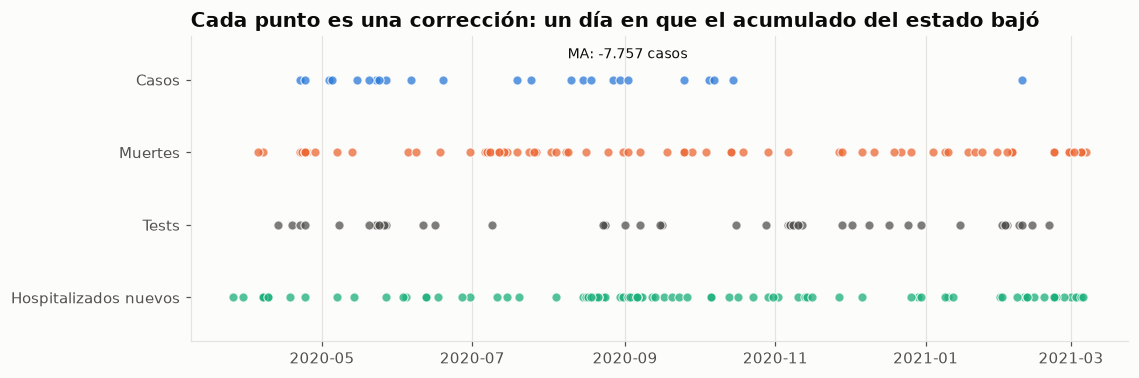

Filas con alguna corrección: 219 | estados y territorios: 44
Por mes: {'2020-03': 2, '2020-04': 19, '2020-05': 18, '2020-06': 14, '2020-07': 18, '2020-08': 25, '2020-09': 23, '2020-10': 17, '2020-11': 18, '2020-12': 13, '2021-01': 12, '2021-02': 30, '2021-03': 10}


In [8]:
etiquetas = {"casos_nuevos": "Casos", "muertes_nuevas": "Muertes", "tests_nuevos": "Tests",
             "hospitalizados_nuevos": "Hospitalizados nuevos"}
colores = {"casos_nuevos": AZUL, "muertes_nuevas": NARANJA, "tests_nuevos": TEXTO_SUAVE,
           "hospitalizados_nuevos": VERDE}

fig, ax = plt.subplots(figsize=(11, 3.6))
for posicion, columna in enumerate(etiquetas):
    negativos = sin_limpiar[sin_limpiar[columna] < 0]
    ax.scatter(negativos["fecha"], [posicion] * len(negativos), s=36, color=colores[columna], alpha=0.75,
               edgecolor="white", linewidth=0.8, zorder=3)
ax.set_yticks(range(len(etiquetas)), list(etiquetas.values()))
ax.set_ylim(len(etiquetas) - 0.4, -0.6)
ax.grid(axis="y", visible=False)
ax.set_title("Cada punto es una corrección: un día en que el acumulado del estado bajó")
ma = sin_limpiar.loc[sin_limpiar["casos_nuevos"].idxmin()]
ax.annotate(f"{ma['estado']}: {formato_miles(ma['casos_nuevos'])} casos", (ma["fecha"], 0), xytext=(0, 14),
            textcoords="offset points", ha="center", fontsize=9, color=TEXTO)
plt.show()

por_mes = sin_limpiar[(sin_limpiar[COLUMNAS_INCREMENTO] < 0).any(axis=1)]
print("Filas con alguna corrección:", len(por_mes), "| estados y territorios:", por_mes["estado"].nunique())
print("Por mes:", por_mes["fecha"].dt.strftime("%Y-%m").value_counts().sort_index().to_dict())

- **Hay correcciones durante todo el periodo**, entre 10 y 30 al mes desde abril de 2020. No es un problema del principio que
  desaparezca después: los estados revisaban sus cifras continuamente.
- **Casi todas son pequeñas.** La mayor en casos es la de **Massachusetts el 2 de septiembre de 2020**
  (−7.757), una revisión de golpe de su serie. En muertes, la mayor resta 201 (Pensilvania, abril de 2020).
- Las de **hospitalizados nuevos** son las más frecuentes (88), lo que confirma la decisión del notebook 02 de no
  usar esa columna.
- Las de tests restan más en número (unos 660.000 en total), pero son muy poco frente a los más de 360 millones de
  tests del periodo.

**Tratamiento (ya aplicado en el notebook 01):** el valor negativo pasa a `NaN` y la fila queda marcada en
`es_correccion`. No se borra la fila, porque el resto de sus columnas son válidas, ni se pone un 0, porque no
sabemos cuántos casos hubo de verdad ese día. Los acumulados no se tocan: ya incluyen la corrección.

**Qué efecto tiene:** al quitar las restas, la suma de los incrementos queda un poco por encima del acumulado
oficial. Lo medimos en los 50 estados y DC:

In [9]:
estados = datos[~datos["es_territorio"]].copy()
diferencias = diferencia_totales(estados)
diferencias.style.format({"suma_incrementos": formato_miles, "ultimo_acumulado": formato_miles,
                          "diferencia": formato_miles, "diferencia_pct": "{:.2f} %"})

,suma_incrementos,ultimo_acumulado,diferencia,diferencia_pct
incremento,,,,
casos_nuevos,28.652.670,28.644.249,8.421,0.03 %
muertes_nuevas,513.972,512.929,1.043,0.20 %
tests_nuevos,363.890.935,363.228.288,662.647,0.18 %


La suma de los incrementos supera al acumulado oficial en un **0,03 % en casos y un 0,2 % en muertes y tests**.
No cambia ninguna conclusión. Aun así, cuando haga falta la **cifra oficial exacta** de un estado, hay que usar su
último acumulado y no la suma de los incrementos.

## 4. Días sin publicar: ceros que no son ceros

Un estado que ya llevaba miles de casos no pasa un día entero sin ninguno. Si aparece un 0, lo más probable es que
**ese día no publicara datos** y los sumara al día siguiente.

In [10]:
estados["cero_sin_publicar"] = marcar_ceros_sin_publicar(estados)
ceros = estados[estados["cero_sin_publicar"]]
print("Días con 0 casos en un estado con 1.000 o más acumulados:", len(ceros), "en", ceros["estado"].nunique(), "estados")
print("De ellos, en sábado o domingo:", f"{ceros['fecha'].dt.day_of_week.isin([5, 6]).mean():.0%}")
print()
print("Estados con más días así:", ceros["estado"].value_counts().head(5).to_dict())

# ¿El día siguiente a un cero viene cargado?
estados["casos_7d_centrada"] = estados.groupby("estado")["casos_nuevos"].transform(
    lambda s: s.rolling(7, center=True, min_periods=4).mean())
siguiente = estados.groupby("estado")["casos_nuevos"].shift(-1)
relacion = (siguiente / estados["casos_7d_centrada"])[estados["cero_sin_publicar"]]
print("El día siguiente a un cero tiene, en mediana,", f"{relacion.median():.1f}".replace(".", ","),
      "veces los casos de un día normal")

Días con 0 casos en un estado con 1.000 o más acumulados: 562 en 38 estados
De ellos, en sábado o domingo: 55%

Estados con más días así: {'KS': 173, 'CT': 81, 'LA': 43, 'MI': 36, 'AR': 20}
El día siguiente a un cero tiene, en mediana, 1,8 veces los casos de un día normal


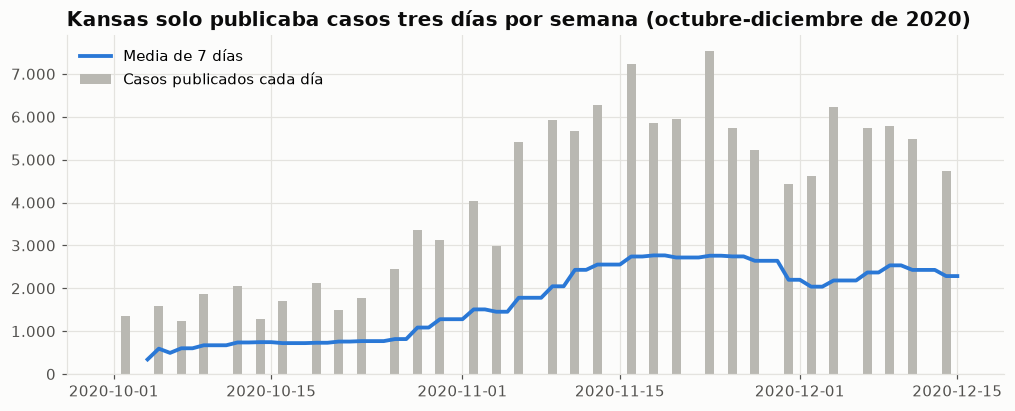

Ceros de Kansas por día de la semana (0 = lunes): {1: 43, 3: 43, 4: 1, 5: 43, 6: 43}


In [11]:
kansas = estados[(estados["estado"] == "KS") & (estados["fecha"].between("2020-10-01", "2020-12-15"))].copy()
kansas["casos_7d"] = kansas["casos_nuevos"].rolling(7, min_periods=4).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(kansas["fecha"], kansas["casos_nuevos"], color=GRIS, width=0.8, label="Casos publicados cada día")
ax.plot(kansas["fecha"], kansas["casos_7d"], color=AZUL, linewidth=2.5, label="Media de 7 días")
ax.yaxis.set_major_formatter(miles)
ax.set_axisbelow(True)
ax.set_title("Kansas solo publicaba casos tres días por semana (octubre-diciembre de 2020)")
ax.legend(loc="upper left")
plt.show()

dias_ks = ceros.loc[ceros["estado"] == "KS", "fecha"].dt.day_of_week.value_counts().sort_index()
print("Ceros de Kansas por día de la semana (0 = lunes):", dias_ks.to_dict())

- Hay **562 días con 0 casos** en estados que ya llevaban más de 1.000, repartidos por 38 estados. Más de la mitad
  caen en fin de semana.
- El día siguiente a un cero tiene, en mediana, **1,8 veces los casos de un día normal**: los casos no
  desaparecen, se publican después.
- El caso extremo es **Kansas**: desde mayo de 2020 solo publicaba los lunes, miércoles y viernes. Sus barras
  diarias saltan de 0 a más de 5.000, pero la media de 7 días dibuja la curva real.

**Tratamiento:** los ceros **no se cambian** (si los pasáramos a `NaN`, los casos del día siguiente seguirían
inflados y el total no cambiaría). Se marcan en `cero_sin_publicar` y se trabaja con la **media de 7 días**, que
reparte cada volcado entre los días de la semana. Es la justificación principal de la siguiente transformación.

## 5. Transformación 1: media móvil de 7 días

### 5.1 Por qué hace falta: el efecto del día de la semana

Además de los días sin publicar, casi todos los estados publicaban menos los fines de semana y recuperaban el
retraso el martes o el miércoles. Lo medimos en la serie nacional: para cada día, cuánto se aparta de la media de
los 7 días que lo rodean (1 = un día normal).

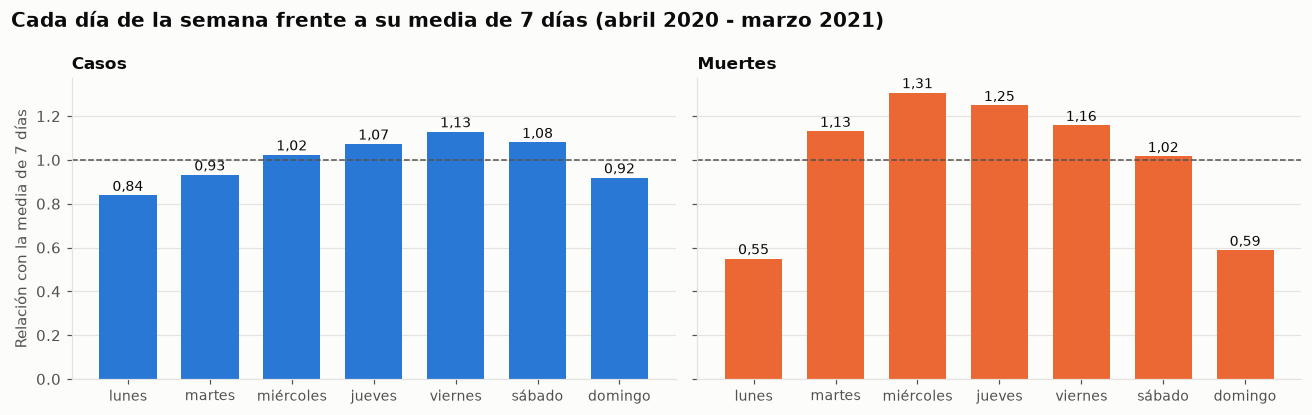

In [12]:
nacional = estados.groupby("fecha")[["casos_nuevos", "muertes_nuevas"]].sum()
nacional = nacional[nacional.index >= "2020-04-01"]   # antes, la serie era demasiado pequeña e irregular
efecto = pd.DataFrame({"casos": efecto_dia_semana(nacional["casos_nuevos"]),
                       "muertes": efecto_dia_semana(nacional["muertes_nuevas"])})

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (columna, color, titulo) in zip(ejes, [("casos", AZUL, "Casos"), ("muertes", NARANJA, "Muertes")]):
    ax.bar(efecto.index, efecto[columna], color=color, width=0.7)
    ax.axhline(1, color=TEXTO_SUAVE, linewidth=1, linestyle="--")
    ax.set_title(titulo, fontsize=11)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", labelsize=9)
    for posicion, valor in enumerate(efecto[columna]):
        ax.text(posicion, valor + 0.02, f"{valor:.2f}".replace(".", ","), ha="center", fontsize=9, color=TEXTO)
ejes[0].set_ylabel("Relación con la media de 7 días")
fig.suptitle("Cada día de la semana frente a su media de 7 días (abril 2020 - marzo 2021)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=TEXTO)
fig.tight_layout()
plt.show()

- **Muertes:** el domingo y el lunes se publica algo más de la mitad de lo normal (0,59 y 0,55), y el martes un
  31 % más. No es que se muera menos en domingo: es que las oficinas no publican.
- **Casos:** el efecto es menor, pero el lunes se queda en 0,84 y el viernes sube a 1,13.

Una serie diaria sin suavizar mezcla la epidemia con el calendario de las oficinas.

### 5.2 Cómo se aplica

`media_movil()` calcula, **dentro de cada estado**, la media de los últimos 7 días:

- **7 días** porque el ciclo es semanal: cada media contiene exactamente un lunes, un martes... y un domingo, así
  que el efecto del día de la semana se cancela.
- **Hacia atrás** (el día y los 6 anteriores), no centrada: cada valor solo usa datos que ya se conocían ese día,
  como en los paneles de seguimiento reales. El precio es que la curva va unos 3 días por detrás.
- **Con un mínimo de 4 días con dato**, para que una corrección suelta (`NaN`) no deje la semana vacía.
- **Por estado**, para no mezclar el final de un estado con el principio del siguiente.

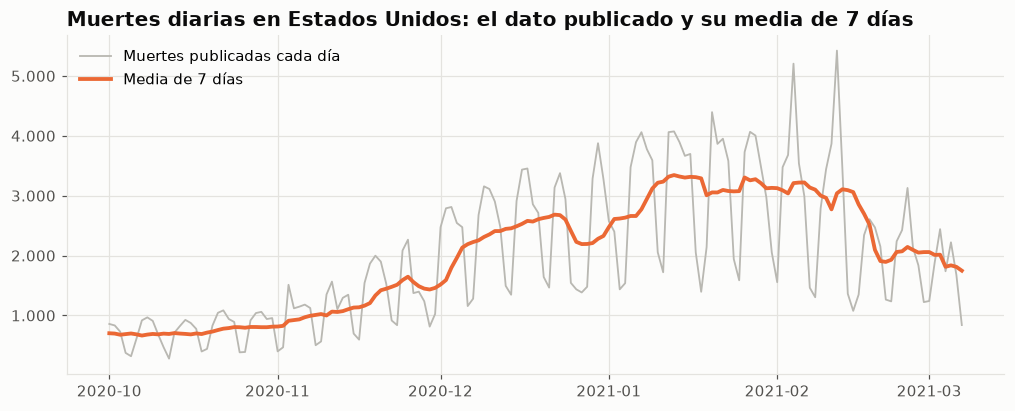

Cambio medio de un día al siguiente: publicadas 535 | media de 7 días 53


In [13]:
estados = media_movil(estados, ["casos_nuevos", "muertes_nuevas"])
nacional = estados.groupby("fecha")[["muertes_nuevas", "muertes_nuevas_7d"]].sum(min_count=1)
nacional = nacional[nacional.index >= "2020-10-01"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(nacional.index, nacional["muertes_nuevas"], color=GRIS, linewidth=1.2, label="Muertes publicadas cada día")
ax.plot(nacional.index, nacional["muertes_nuevas_7d"], color=NARANJA, linewidth=2.5, label="Media de 7 días")
ax.yaxis.set_major_formatter(miles)
ax.set_title("Muertes diarias en Estados Unidos: el dato publicado y su media de 7 días")
ax.legend(loc="upper left")
plt.show()

oscilacion = nacional.diff().abs().mean()
print("Cambio medio de un día al siguiente: publicadas", formato_miles(oscilacion["muertes_nuevas"]),
      "| media de 7 días", formato_miles(oscilacion["muertes_nuevas_7d"]))

La línea gris sube y baja cada semana (y tiene el pico de más de 5.000 del atraso de Ohio en febrero). La media
de 7 días deja ver la tendencia: la subida de otoño, el pico de enero y la bajada. De un día al siguiente, la
serie publicada cambia de media unas 10 veces más que la suavizada (535 muertes frente a 53).

Por eso **todas las series temporales del proyecto usan la media de 7 días**, y los totales se calculan con las
cifras diarias sin suavizar (la media móvil no cambia la suma, solo la reparte).

## 6. Transformación 2: escala logarítmica para las distribuciones sesgadas

### 6.1 El problema: casi todo está a la izquierda

Los casos diarios de un estado van de 0 a más de 70.000. La mayoría de los días son pequeños (estados pequeños o
fuera de las olas), y unos pocos, enormes (California o Texas en invierno). Lo medimos con la **asimetría**
(*skew*): 0 es una distribución simétrica y, por encima de 1, ya es muy sesgada.

In [14]:
variables = ["casos_nuevos", "muertes_nuevas", "tests_nuevos", "hospitalizados_actuales"]
tabla_asimetria = asimetria(estados, variables)
tabla_asimetria.round(2)

,asimetria_original,asimetria_log
casos_nuevos,6.80,-0.96
muertes_nuevas,9.27,0.21
tests_nuevos,4.58,-1.78
hospitalizados_actuales,4.54,-0.50


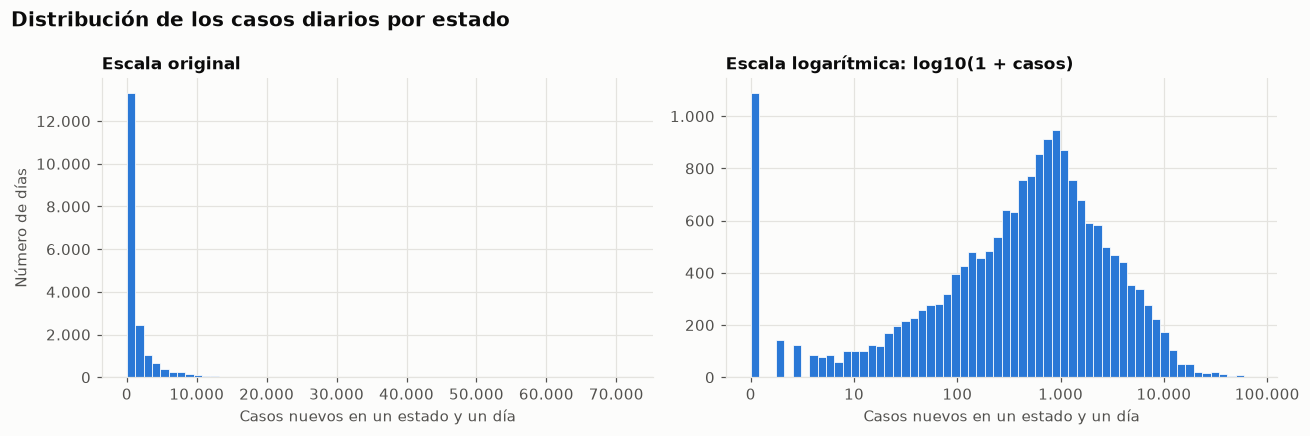

Días con 0 casos: 5,7%


In [15]:
casos = estados["casos_nuevos"].dropna()

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].hist(casos, bins=60, color=AZUL, edgecolor="white", linewidth=0.5)
ejes[0].set_title("Escala original", fontsize=11)
ejes[0].xaxis.set_major_formatter(miles)
ejes[0].yaxis.set_major_formatter(miles)
ejes[0].set_xlabel("Casos nuevos en un estado y un día")
ejes[0].set_ylabel("Número de días")

ejes[1].hist(log10_1p(casos), bins=60, color=AZUL, edgecolor="white", linewidth=0.5)
ejes[1].set_title("Escala logarítmica: log10(1 + casos)", fontsize=11)
ejes[1].set_xticks(range(6), ["0", "10", "100", "1.000", "10.000", "100.000"])
ejes[1].set_xlabel("Casos nuevos en un estado y un día")
ejes[1].yaxis.set_major_formatter(miles)
for ax in ejes:
    ax.set_axisbelow(True)
fig.suptitle("Distribución de los casos diarios por estado", x=0.01, ha="left", fontsize=13, fontweight="bold",
             color=TEXTO)
fig.tight_layout()
plt.show()

print("Días con 0 casos:", f"{(casos == 0).mean():.1%}".replace(".", ","))

- **En la escala original** casi todos los días quedan en la primera barra y el resto del gráfico es la cola de
  unos pocos días enormes. No se ve la forma de la distribución.
- **En la escala logarítmica** cada marca del eje es 10 veces la anterior. La distribución se abre y se ve que lo
  típico es un estado con entre 100 y 10.000 casos al día. La asimetría de los casos baja de 6,8 a −1,0.
- Queda a la izquierda la barra de los **días con 0 casos**: son sobre todo los días sin publicar del apartado 4 y
  el principio de la pandemia.

**Por qué `log10(1 + x)` y no `log10(x)`:** el logaritmo de 0 no existe, y hay muchos días con 0 casos. Sumar 1
deja el 0 en el 0 y apenas cambia los valores grandes.

**Cuándo la usamos:** para **ver distribuciones** y comparar estados de tamaños muy distintos en un mismo gráfico
(ya la usamos en el notebook 02, en el boxplot por estados). No la usamos para calcular totales ni medias, que se
hacen siempre en la escala original.

### 6.2 Otra forma de reducir el sesgo: normalizar por población

Parte del sesgo viene de mezclar estados de tamaños muy distintos. Si en vez de casos usamos **casos por cada
100.000 habitantes** (notebook 05), la asimetría también baja sin necesidad de logaritmos:

In [16]:
print("Asimetría de los casos diarios (media de 7 días):            ",
      round(estados["casos_nuevos_7d"].skew(), 2))
print("Asimetría de los casos por 100.000 habitantes (media de 7 días):",
      round(estados["casos_100k_7d"].skew(), 2))

Asimetría de los casos diarios (media de 7 días):             6.21
Asimetría de los casos por 100.000 habitantes (media de 7 días): 1.77


Normalizar por población quita la parte del sesgo que se debe al tamaño de los estados. La que queda se debe a
las olas: unas pocas semanas de enero de 2021 con muchos más casos que el resto del año.

## 7. Resumen: cada tipo de dato dudoso y su tratamiento

| Tipo | Ejemplo | Cuántos | Tratamiento | Notebook |
|---|---|---|---|---|
| Columnas casi vacías o repetidas | Desglose de tests por tipo, `posNeg` | 41 de 56 columnas | Se descartan | 01 |
| Nulos al principio de cada serie | Acumulados antes de que el estado publicara | ≤ 4 % de las filas | No se imputan: significan "aún no se publicaba" | 01, 02 |
| Incrementos negativos (correcciones) | Massachusetts, −7.757 casos el 02-09-2020 | 219 filas | El valor pasa a `NaN` y se marca en `es_correccion`; los acumulados no se tocan | 01, 06 |
| Más positivos que tests | Washington, Michigan y Georgia antes del 25-03-2020 | 59 filas | Los tests de la fila pasan a `NaN`; se marca en `positivos_sobre_tests` | 06 |
| Positividad por encima del 100 % | Michigan, marzo de 2020 | 17 filas (4 tras corregir los tests) | Pasa a `NaN` | 03, 06 |
| Más pacientes con respirador que en UCI | Puerto Rico | 57 filas | Se marca en `ventilador_sobre_uci`; columna no usada en conclusiones | 06 |
| Recuperados más muertes por encima de los casos | Iowa | 69 filas | Se marca en `recuperados_sobre_casos`; columna no usada en conclusiones | 06 |
| Días sin publicar | Kansas publicaba 3 días por semana | 562 días en 38 estados | Se marcan en `cero_sin_publicar`; se usa la media de 7 días | 06 |
| Atrasos de notificación | Ohio, 2.559 muertes el 12-02-2021 | 8 en casos, 58 en muertes | Se mantienen y se marcan (`atraso_*`) | 02 |
| Efecto del día de la semana | Muertes del lunes al 55 % de lo normal | Toda la serie | Media de 7 días en las series temporales | 06 |
| Distribuciones muy sesgadas | Casos diarios: asimetría 6,8 | Todas las variables diarias | Escala logarítmica para verlas; tasas por habitante para comparar | 02, 05, 06 |

**Qué queda pendiente:**

- La suma de los incrementos supera al acumulado oficial en un 0,03 % (casos) y un 0,2 % (muertes) por las
  correcciones quitadas. Para cifras oficiales exactas hay que usar el último acumulado.
- El criterio de atrasos solo detecta los volcados más claros (notebook 02).
- Los tests y los hospitalizados se contaban de forma distinta en cada estado: se pueden ver tendencias dentro de
  un estado, pero las comparaciones entre estados son aproximadas.

## 8. Aplicar los tratamientos y guardar

`tratar_calidad()` añade las marcas nuevas y pasa a `NaN` los tests de las filas con más positivos que tests.
Después recalculamos la positividad con esos tests corregidos.

In [17]:
final = tratar_calidad(datos)
final["positividad_7d"] = positividad_7d(final)

print("Filas cuyos tests pasan a NaN:", int(final["positivos_sobre_tests"].sum()))
print("Positividad por encima del 100 % antes de este tratamiento:",
      int((positividad_7d(datos, maximo=None) > 1).sum()))
print("Positividad por encima del 100 % después:", int((positividad_7d(final, maximo=None) > 1).sum()))
print("Valores de positividad que cambian:",
      int((final["positividad_7d"].fillna(-1) != datos["positividad_7d"].fillna(-1)).sum()))
nuevas = ["positivos_sobre_tests", "ventilador_sobre_uci", "recuperados_sobre_casos", "cero_sin_publicar"]
final[nuevas].sum().to_frame("filas marcadas")

Filas cuyos tests pasan a NaN: 59
Positividad por encima del 100 % antes de este tratamiento: 17
Positividad por encima del 100 % después: 4
Valores de positividad que cambian: 18


,filas marcadas
positivos_sobre_tests,59
ventilador_sobre_uci,57
recuperados_sobre_casos,69
cero_sin_publicar,640


- Al quitar los tests imposibles, la positividad por encima del 100 % baja de 17 valores a 4. Los 4 que quedan no
  vienen de acumulados incoherentes, sino de semanas en las que casi no se publicaron tests: tres de las Islas
  Marianas del Norte (agosto de 2020, con muy pocos casos y tests) y uno de Washington el 28-11-2020, después de Acción de
  Gracias. Siguen pasando a `NaN` con el tope del 100 % del notebook 03.
- `cero_sin_publicar` marca 640 filas: las 562 de los estados más las de los territorios.

In [18]:
RUTA_FINAL = RAIZ / "data" / "processed" / "covid_estados_final.csv"
final.to_csv(RUTA_FINAL, index=False)
print("Guardado:", RUTA_FINAL.relative_to(RAIZ), final.shape)

Guardado: data\processed\covid_estados_final.csv (20780, 36)


## Conclusiones

- **Las dos familias de columnas son coherentes:** el incremento diario es siempre la diferencia de los
  acumulados. Los 219 incrementos negativos son días en que el estado corrigió cifras anteriores, repartidos por
  todo el periodo.
- **Los datos imposibles son pocos y están localizados:** más positivos que tests solo en tres estados y en
  marzo de 2020; respiradores por encima de la UCI sobre todo en Puerto Rico; recuperados imposibles solo en
  Iowa. Cada uno está marcado y tratado.
- **Los ceros no siempre son ceros:** 562 días sin casos en estados con miles de casos son días sin publicar; los
  casos llegan al día siguiente.
- **Media móvil de 7 días:** las oficinas publicaban menos el fin de semana (las muertes del lunes se quedan en
  el 55 % de lo normal). Una media de 7 días contiene una semana completa y cancela ese efecto.
- **Escala logarítmica:** los casos diarios por estado tienen una asimetría de 6,8; con `log10(1 + x)` baja a
  −1,0 y se puede ver la distribución. Para comparar estados, además, conviene usar tasas por habitante.